# Exploratory Data Analysis of House Prices
### Ames Housing Dataset — Pure EDA (No Machine Learning)

**Objective:** Perform a complete exploratory data analysis (EDA) workflow on the Ames Housing dataset to understand which factors drive house sale prices—without fitting any machine-learning models.

**Dataset:** Kaggle *House Prices: Advanced Regression Techniques* (`train.csv`, 1,460 rows and 81 columns).

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy, Jupyter Notebook.

---

## Problem Statement and Guiding Questions

Before touching the data, we establish six guiding questions to structure the analysis:

1. **Distribution:** How is `SalePrice` distributed? Is it skewed?
2. **Numerical Drivers:** Which numerical features correlate most strongly with `SalePrice`?
3. **Quality Effect:** Does overall quality (`OverallQual`) change price in a clear, ordered way?
4. **Location Effect:** Do some neighborhoods consistently cost more than others?
5. **Outliers:** Are there outliers, and are they data errors or real but unusual sales?
6. **Missingness:** Which columns have missing values, and which of those are not truly missing (i.e., "feature absent")?

## Variable Reference

| Type | Example Columns |
|---|---|
| **Numerical (continuous)** | `SalePrice`, `GrLivArea`, `LotArea`, `TotalBsmtSF`, `GarageArea` |
| **Numerical (discrete)** | `YearBuilt`, `YrSold`, `FullBath`, `BedroomAbvGr` |
| **Categorical (nominal)** | `Neighborhood`, `HouseStyle`, `SaleCondition`, `MSZoning` |
| **Ordinal** | `OverallQual` (1 to 10), `ExterQual` and `KitchenQual` (`Po < Fa < TA < Gd < Ex`) |

## 2. Data Loading (Step 1: Setup and First Look)

**What we are about to do:**  
Import the core data-analysis and visualisation libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy.stats`), configure a clean plotting style and default figure size, load `train.csv`, and inspect the dataset's shape, first 5 rows, column types/non-null counts (`info`), and all columns with missing values sorted in descending order with percentages.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

for data_path in [
    "train.csv",
    "/kaggle/input/house-prices-advanced-regression-techniques/train.csv",
    "/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv",
]:
    if os.path.exists(data_path):
        df = pd.read_csv(data_path)
        print(f"Loaded data from: {data_path}")
        break
else:
    raise FileNotFoundError("train.csv not found locally or in /kaggle/input/")

print("Shape of dataset:", df.shape)
display(df.head())
print("\n--- DataFrame Info ---")
df.info()

missing = df.isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0]
missing_df = pd.DataFrame({
    "MissingCount": missing,
    "MissingPercent": (missing / len(df) * 100).round(2)
})
print(f"\nColumns with missing values: {len(missing_df)} out of {df.shape[1]}")
display(missing_df)

Loaded data from: train.csv
Shape of dataset: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000



--- DataFrame Info ---
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  


,MissingCount,MissingPercent
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageYrBlt,81,5.55
GarageCond,81,5.55
GarageType,81,5.55


### Deliverable — Step 1 Summary & First Impressions

- **Shape:** `train.csv` contains **1,460 rows** and **81 columns** (`Id`, 79 explanatory features, and the target `SalePrice`).
- **Missing values:** **19 columns** contain missing values (`NaN`).
  - The highest missingness occurs in `PoolQC` (99.52%, 1,453 missing), `MiscFeature` (96.30%, 1,406), `Alley` (93.77%, 1,369), `Fence` (80.75%, 1,179), `MasVnrType` (59.73%, 872), and `FireplaceQu` (47.26%, 690).
  - Garage-related columns (`GarageType`, `GarageYrBlt`, `GarageFinish`, `GarageQual`, `GarageCond`) are each missing in exactly **81 rows (5.55%)**, and basement-related columns (`BsmtQual`, `BsmtCond`, `BsmtFinType1`, `BsmtExposure`, `BsmtFinType2`) are missing in **37–38 rows (2.53%–2.60%)**.
  - True numeric/operational missingness appears small: `LotFrontage` (259 rows, 17.74%), `MasVnrArea` (8 rows, 0.55%), and `Electrical` (1 row, 0.07%).
- **First impressions:** Most missing values reflect homes that simply *do not have* the corresponding amenity (no pool, no alley, no fence, no fireplace, no garage, no basement) rather than lost data—dropping those rows or columns blindly would discard valid records and important structural information.

## 3. Data Understanding (Steps 2 & 3)

### Step 2: Classify Variables

**What we are about to do:**  
Split the 81 columns into numerical and categorical groups, explicitly convert `ExterQual` and `KitchenQual` into ordered `pd.Categorical` variables (`Po < Fa < TA < Gd < Ex`), and build a variable summary table showing each column's name, semantic variable type, number of unique values, and example values.

In [2]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

ordinal_order = ["Po", "Fa", "TA", "Gd", "Ex"]
ordinal_map = {
    "ExterQual": ordinal_order,
    "KitchenQual": ordinal_order,
}

for col, order in ordinal_map.items():
    df[col] = pd.Categorical(df[col], categories=order, ordered=True)

discrete_numeric = {
    "Id", "MSSubClass", "OverallQual", "OverallCond", "YearBuilt", "YearRemodAdd",
    "BsmtFullBath", "BsmtHalfBath", "FullBath", "HalfBath", "BedroomAbvGr",
    "KitchenAbvGr", "TotRmsAbvGrd", "Fireplaces", "GarageYrBlt", "GarageCars",
    "MoSold", "YrSold"
}

def classify_column(col: str) -> str:
    if col in ("OverallQual", "OverallCond"):
        return "Ordinal (stored as numeric)"
    if col in ordinal_map:
        return "Ordinal (ordered categorical)"
    if col in numeric_cols:
        return "Numerical (discrete)" if col in discrete_numeric else "Numerical (continuous)"
    return "Categorical (nominal)"

summary_table = pd.DataFrame({
    "Column": df.columns,
    "Type": [classify_column(c) for c in df.columns],
    "UniqueValues": [df[c].nunique(dropna=True) for c in df.columns],
    "ExampleValues": [", ".join(map(str, df[c].dropna().unique()[:4])) for c in df.columns],
})

print(f"Numeric dtype columns: {len(numeric_cols)} | Non-numeric dtype columns: {len(categorical_cols)}")
display(summary_table["Type"].value_counts().to_frame("ColumnCount"))
display(summary_table.head(30))
display(summary_table.tail(25))

Numeric dtype columns: 38 | Non-numeric dtype columns: 43


,ColumnCount
Type,
Categorical (nominal),41
Numerical (continuous),20
Numerical (discrete),16
Ordinal (stored as numeric),2
Ordinal (ordered categorical),2


,Column,Type,UniqueValues,ExampleValues
0,Id,Numerical (discrete),1460,"1, 2, 3, 4"
1,MSSubClass,Numerical (discrete),15,"60, 20, 70, 50"
2,MSZoning,Categorical (nominal),5,"RL, RM, C (all), FV"
3,LotFrontage,Numerical (continuous),110,"65.0, 80.0, 68.0, 60.0"
4,LotArea,Numerical (continuous),1073,"8450, 9600, 11250, 9550"
5,Street,Categorical (nominal),2,"Pave, Grvl"
6,Alley,Categorical (nominal),2,"Grvl, Pave"
7,LotShape,Categorical (nominal),4,"Reg, IR1, IR2, IR3"
8,LandContour,Categorical (nominal),4,"Lvl, Bnk, Low, HLS"
9,Utilities,Categorical (nominal),2,"AllPub, NoSeWa"


,Column,Type,UniqueValues,ExampleValues
56,Fireplaces,Numerical (discrete),4,"0, 1, 2, 3"
57,FireplaceQu,Categorical (nominal),5,"TA, Gd, Fa, Ex"
58,GarageType,Categorical (nominal),6,"Attchd, Detchd, BuiltIn, CarPort"
59,GarageYrBlt,Numerical (discrete),97,"2003.0, 1976.0, 2001.0, 1998.0"
60,GarageFinish,Categorical (nominal),3,"RFn, Unf, Fin"
61,GarageCars,Numerical (discrete),5,"2, 3, 1, 0"
62,GarageArea,Numerical (continuous),441,"548, 460, 608, 642"
63,GarageQual,Categorical (nominal),5,"TA, Fa, Gd, Ex"
64,GarageCond,Categorical (nominal),5,"TA, Fa, Gd, Po"
65,PavedDrive,Categorical (nominal),3,"Y, N, P"


**What we learned (Step 2):**  
- Of the 81 columns, **38** are stored with numeric dtypes (`int64` / `float64`) and **43** with string/categorical dtypes.
- `ExterQual` and `KitchenQual` are now properly encoded as ordered categoricals (`Po < Fa < TA < Gd < Ex`), preserving their natural quality hierarchy.
- **Important note on `OverallQual`:** `OverallQual` (and `OverallCond`) is stored as an integer from **1 to 10**, so `select_dtypes(include=np.number)` groups it with numerical columns. Conceptually, however, it is an **ordinal** quality rating—differences between consecutive integers represent ordered quality tiers rather than strictly equal dollar/physical units.

### Step 3: Descriptive Statistics

**What we are about to do:**  
Display `df.describe()` across numerical columns, compute centre and spread metrics (mean, median, mode, standard deviation, variance, range, IQR, skewness, and kurtosis) for `SalePrice`, `GrLivArea`, and `LotArea`, check skewness direction using `mean` vs `median`, and examine frequency distributions (`value_counts` and mode) for `Neighborhood` and `HouseStyle`.

In [3]:
display(df.describe().T)

stats_rows = []
for col in ["SalePrice", "GrLivArea", "LotArea"]:
    s = df[col].dropna()
    mean_val = s.mean()
    median_val = s.median()
    mode_val = s.mode().iloc[0]
    std_val = s.std()
    var_val = s.var()
    range_val = s.max() - s.min()
    iqr_val = s.quantile(0.75) - s.quantile(0.25)
    skew_val = s.skew()
    kurt_val = s.kurt()
    if mean_val > median_val:
        skew_note = "Right skewed (mean > median)"
    elif mean_val < median_val:
        skew_note = "Left skewed (mean < median)"
    else:
        skew_note = "Symmetric (mean == median)"

    stats_rows.append({
        "Feature": col,
        "Mean": round(mean_val, 2),
        "Median": round(median_val, 2),
        "Mode": mode_val,
        "Std": round(std_val, 2),
        "Variance": round(var_val, 2),
        "Range": range_val,
        "IQR": round(iqr_val, 2),
        "Skewness": round(skew_val, 4),
        "Kurtosis": round(kurt_val, 4),
        "Direction": skew_note,
    })

display(pd.DataFrame(stats_rows).set_index("Feature"))

for col in ["Neighborhood", "HouseStyle"]:
    print(f"\n--- {col} (Mode: {df[col].mode().iloc[0]}) ---")
    display(df[col].value_counts().to_frame("Count"))

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


,Mean,Median,Mode,Std,Variance,Range,IQR,Skewness,Kurtosis,Direction
Feature,,,,,,,,,,
SalePrice,180921.20,163000.0,140000,79442.50,6.311111e+09,720100,84025.00,1.8829,6.5363,Right skewed (mean > median)
GrLivArea,1515.46,1464.0,864,525.48,2.761296e+05,5308,647.25,1.3666,4.8951,Right skewed (mean > median)
LotArea,10516.83,9478.5,7200,9981.26,9.962565e+07,213945,4048.00,12.2077,203.2433,Right skewed (mean > median)



--- Neighborhood (Mode: NAmes) ---


,Count
Neighborhood,
NAmes,225
CollgCr,150
OldTown,113
Edwards,100
Somerst,86
Gilbert,79
NridgHt,77
Sawyer,74
NWAmes,73



--- HouseStyle (Mode: 1Story) ---


,Count
HouseStyle,
1Story,726
2Story,445
1.5Fin,154
SLvl,65
SFoyer,37
1.5Unf,14
2.5Unf,11
2.5Fin,8


**What we learned (Step 3):**  
- All three key continuous variables are **right-skewed** (`mean > median`):
  - `SalePrice`: Mean = **\$180,921.20**, Median = **\$163,000.00**, Mode = **\$140,000**, Std = **\$79,442.50**, IQR = **\$84,025.00**, Skewness = **1.8829**, Kurtosis = **6.5363**.
  - `GrLivArea`: Mean = **1,515.46 sq ft**, Median = **1,464.00 sq ft**, Mode = **864 sq ft**, Skewness = **1.3666**, Kurtosis = **4.8951**.
  - `LotArea`: Mean = **10,516.83 sq ft**, Median = **9,478.50 sq ft**, Mode = **7,200 sq ft**, Skewness = **12.2077**, Kurtosis = **203.2433** (driven by a few huge estate/acreage lots up to 215,245 sq ft).
- For categorical counts, **NAmes** (225 homes) is the modal `Neighborhood` (followed by `CollgCr` with 150 and `OldTown` with 113), while **1Story** (726 homes) and **2Story** (445 homes) dominate `HouseStyle`.

**Interpretation prompt — What does the gap between mean and median of `SalePrice` tell you?**  
The mean (\$180,921) exceeds the median (\$163,000) by **\$17,921** (about 11% of the median). Because the arithmetic mean is sensitive to extreme upper-tail values while the median is resistant to them, this positive gap indicates that a smaller number of high-priced luxury homes pull the average upward. Practically, the **median** (\$163,000) and **IQR** (\$84,025) describe a "typical" Ames house far more faithfully than the mean and standard deviation.

## 4. Data Cleaning & Quality Checks (Step 9)

*(Following the suggested notebook structure, we run data quality checks and missing-value handling early so all subsequent analyses operate on a clean, consistent dataset while preserving raw distributions of key variables like `SalePrice` and `GrLivArea`.)*

**What we are about to do:**  
1. Check for exact duplicate rows (`duplicated().sum()`) and drop any if present.
2. Inspect all categorical columns for inconsistent casing (e.g., `"Gd"` vs `"gd"`), leading/trailing whitespace, or near-duplicate spellings.
3. Document and apply explicit missing-value strategies:
   - Replace `NaN` with `"None"` for columns where `NA` means **"feature absent"** (`PoolQC`, `MiscFeature`, `Alley`, `Fence`, `MasVnrType`, `FireplaceQu`, `GarageType`, `GarageFinish`, `GarageQual`, `GarageCond`, `BsmtQual`, `BsmtCond`, `BsmtFinType1`, `BsmtExposure`, `BsmtFinType2` — while noting two single-row basement edge cases).
   - Impute `LotFrontage` using the **median grouped by `Neighborhood`** (with overall median fallback).
   - Fill `MasVnrArea` (8 rows where `MasVnrType` is absent) with `0`, `GarageYrBlt` (81 rows with no garage) with `0` (while recording a `HasGarage` indicator or keeping track), and `Electrical` (1 missing row) with its mode (`"SBrkr"`).
4. Verify remaining missing count across the entire DataFrame is **0**, and check for impossible values (`YearBuilt > YrSold`, `YearRemodAdd > YrSold`, negative areas).

In [4]:
# 1. Duplicate check
dup_count = df.duplicated().sum()
print("Duplicate rows:", dup_count)
if dup_count > 0:
    df = df.drop_duplicates().copy()
    print("New shape after removing duplicates:", df.shape)

# 2. Check categorical columns for casing, whitespace, or spelling inconsistencies
cat_check_cols = df.select_dtypes(exclude=np.number).columns.tolist()
inconsistencies = []
for col in cat_check_cols:
    vals = df[col].dropna().astype(str).unique().tolist()
    stripped_lower = [v.strip().lower() for v in vals]
    has_whitespace = any(v != v.strip() for v in vals)
    has_case_collision = len(set(stripped_lower)) != len(vals)
    if has_whitespace or has_case_collision:
        inconsistencies.append((col, vals))

print("Categorical columns with casing/whitespace collisions:", len(inconsistencies))
if inconsistencies:
    for col, vals in inconsistencies:
        print(f"  Issue in {col}: {vals}")
else:
    print("  All categorical labels have consistent casing and no leading/trailing spaces.")

# 3. Handle missing values with documented domain decisions
# 3a. Feature-absent categorical columns -> "None"
absence_cols = [
    "PoolQC", "MiscFeature", "Alley", "Fence", "MasVnrType", "FireplaceQu",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond", "BsmtFinType1", "BsmtExposure", "BsmtFinType2"
]
for col in absence_cols:
    df[col] = df[col].fillna("None")

# 3b. Numeric missing values
# LotFrontage: fill with Neighborhood median (captures street-frontage norms per area)
df["LotFrontage"] = df["LotFrontage"].fillna(
    df.groupby("Neighborhood")["LotFrontage"].transform("median")
)
df["LotFrontage"] = df["LotFrontage"].fillna(df["LotFrontage"].median())

# MasVnrArea: the 8 missing rows all have MasVnrType == "None" -> 0 sq ft
df["MasVnrArea"] = df["MasVnrArea"].fillna(0.0)

# GarageYrBlt: 81 rows have no garage (GarageType == "None") -> 0 indicates absent
# (Keep a separate note so 0 is not treated as year 0 in time plots.)
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(0.0)

# 3c. Electrical: 1 missing row -> fill with modal category ("SBrkr")
df["Electrical"] = df["Electrical"].fillna(df["Electrical"].mode().iloc[0])

# Verify zero missing values remain
total_remaining_missing = int(df.isnull().sum().sum())
print("Total remaining missing cells across dataset:", total_remaining_missing)
assert total_remaining_missing == 0, "Expected zero remaining missing values!"

# 4. Check impossible values
print("\n--- Impossible Value Checks ---")
print("YearBuilt > YrSold:", int((df["YearBuilt"] > df["YrSold"]).sum()))
print("GarageYrBlt > YrSold:", int((df["GarageYrBlt"] > df["YrSold"]).sum()))
print("YearRemodAdd > YrSold:", int((df["YearRemodAdd"] > df["YrSold"]).sum()))
if (df["YearRemodAdd"] > df["YrSold"]).any():
    display(df.loc[df["YearRemodAdd"] > df["YrSold"],
                   ["Id", "YearBuilt", "YearRemodAdd", "YrSold", "SaleCondition", "GrLivArea", "SalePrice"]])

area_cols = ["LotArea", "GrLivArea", "TotalBsmtSF", "GarageArea", "MasVnrArea", "LotFrontage"]
for col in area_cols:
    neg_count = int((df[col] < 0).sum())
    if neg_count > 0:
        print(f"Negative values in {col}: {neg_count}")
print("Negative area values across checked area columns: 0")

Duplicate rows: 0
Categorical columns with casing/whitespace collisions: 0
  All categorical labels have consistent casing and no leading/trailing spaces.
Total remaining missing cells across dataset: 0

--- Impossible Value Checks ---
YearBuilt > YrSold: 0
GarageYrBlt > YrSold: 0
YearRemodAdd > YrSold: 1


,Id,YearBuilt,YearRemodAdd,YrSold,SaleCondition,GrLivArea,SalePrice
523,524,2007,2008,2007,Partial,4676,184750


Negative area values across checked area columns: 0


**What we learned (Step 9 — Data Cleaning Decisions):**  
- **Duplicates & category consistency:** There are **0 exact duplicate rows**, and **0 categorical columns** suffer from casing collisions (`"Gd"` vs `"gd"`) or stray whitespace.
- **Missing-value documentation:**
  - *Feature-absent categoricals → `"None"`*: `PoolQC`, `MiscFeature`, `Alley`, `Fence`, `MasVnrType`, `FireplaceQu`, `GarageType`, `GarageFinish`, `GarageQual`, `GarageCond`, `BsmtQual`, `BsmtCond`, `BsmtFinType1`, `BsmtExposure`, and `BsmtFinType2` all encode the absence of a feature as `NA` in the Ames documentation, so filling them with `"None"` preserves all 1,460 houses accurately.
  - *Neighborhood-median numeric imputation*: `LotFrontage` (259 missing) was imputed using the median `LotFrontage` within each `Neighborhood`, because lot frontages depend strongly on subdivision layout.
  - *Structural zeros & mode*: `MasVnrArea` (8 missing, all with no masonry veneer) was filled with `0.0`; `GarageYrBlt` (81 missing, all with no garage) was filled with `0.0` (noting that `0` acts as a sentinel for "no garage" rather than a literal calendar year); and `Electrical` (1 missing row, `Id=1380`) was filled with the mode `"SBrkr"`.
  - **Verification:** Remaining missing count across all 81 columns is **0**.
- **Impossible-value check:** Zero rows have negative area measurements or `YearBuilt > YrSold`. One row (`Id=524`) has `YearRemodAdd = 2008 > YrSold = 2007` along with `SaleCondition = "Partial"` and `GrLivArea = 4,676` — a notable data-entry/partial-completion anomaly that will reappear in our outlier analysis!

## 5. Univariate Analysis (Step 4: Distributions)

**What we are about to do:**  
Visualise the distribution of `SalePrice` using a 1×3 figure (histogram with KDE overlay, boxplot, and histogram of `log(SalePrice)` comparing skewness before and after transformation), inspect how `SalePrice` varies across `OverallQual` and across `Neighborhood` (sorted by median price with 90°-rotated x-axis labels), and plot countplots for `OverallQual` and `HouseStyle`.

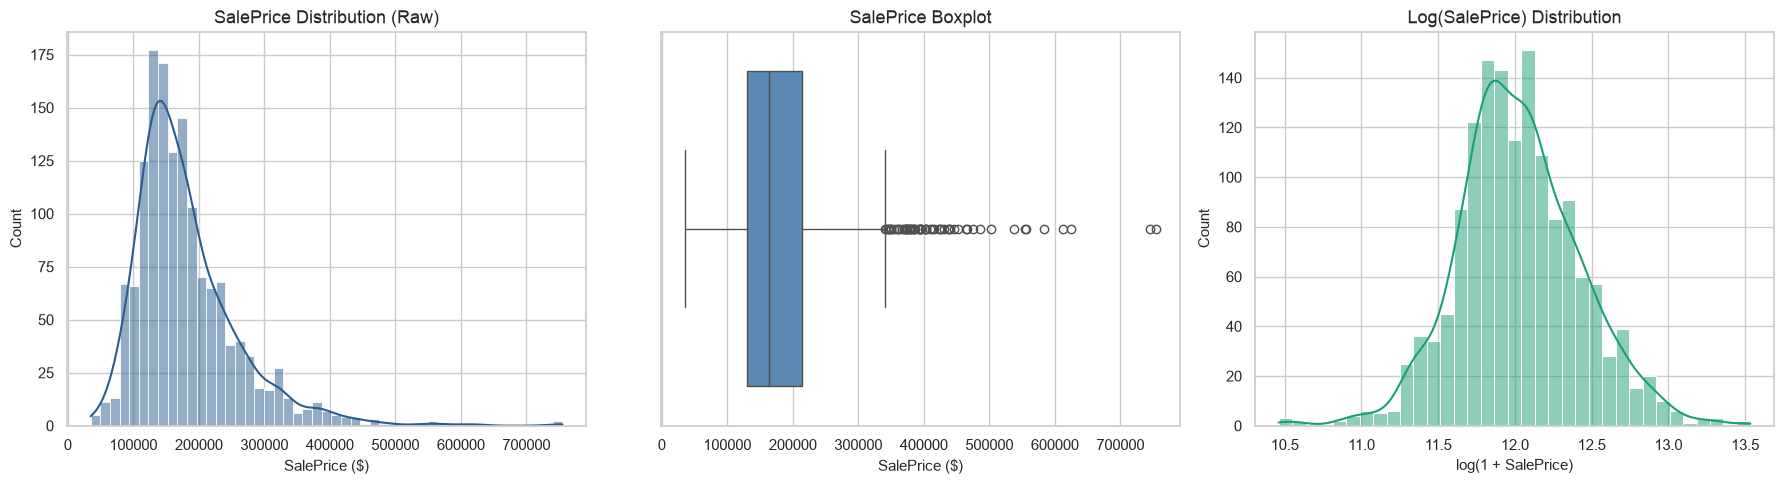

Skewness before log transform: 1.8829
Skewness after log transform:  0.1213


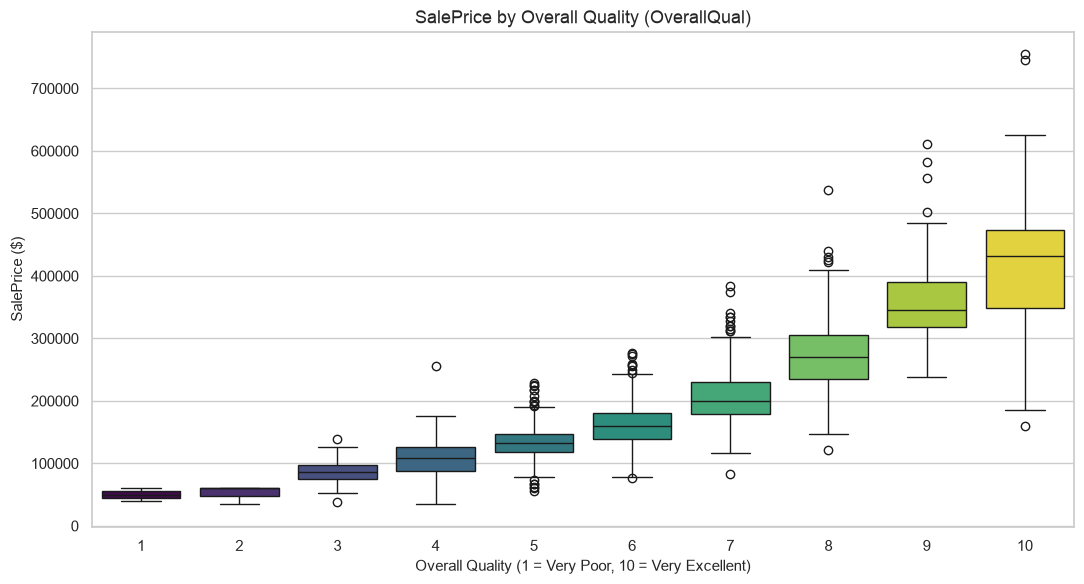

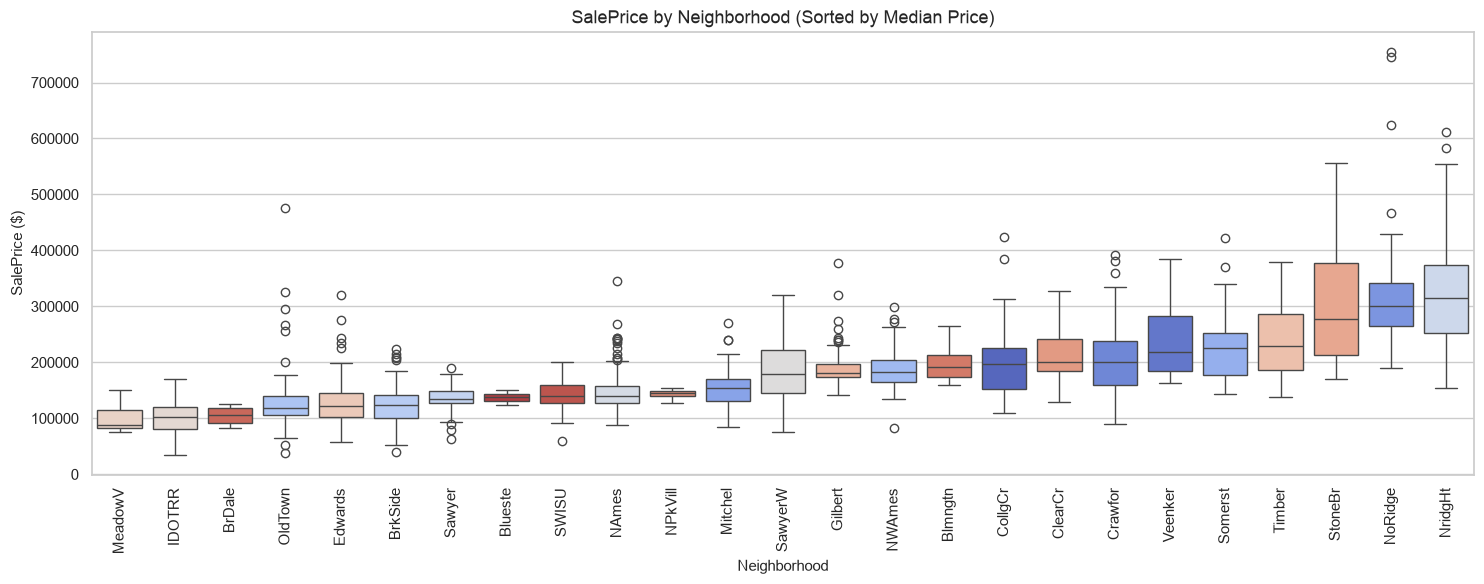

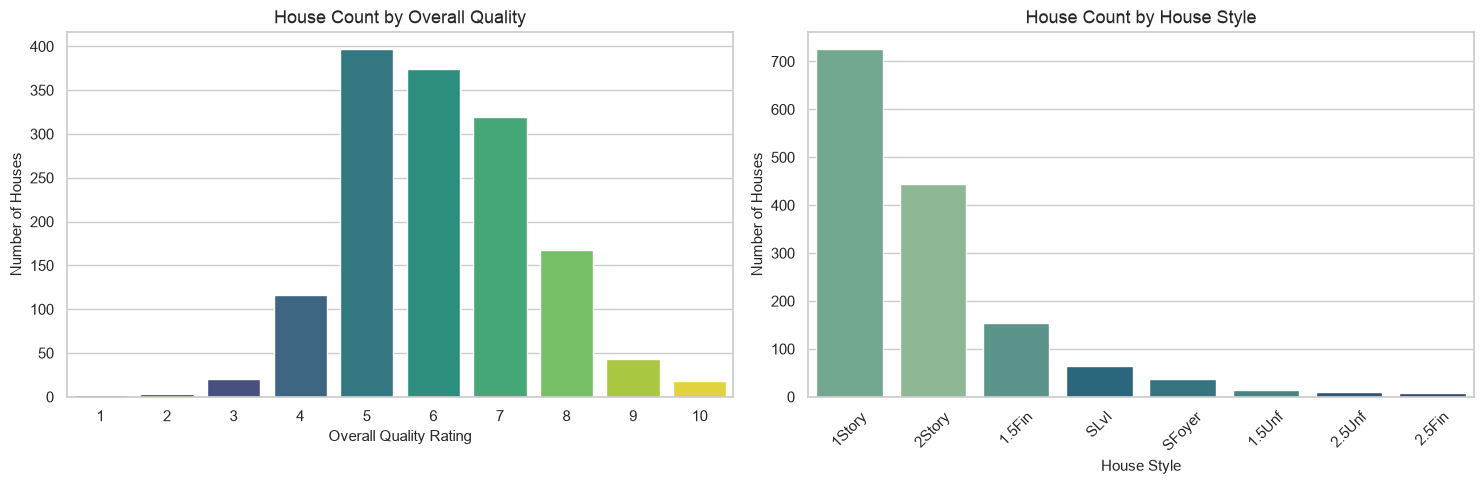

In [5]:
# 1x3 figure: SalePrice distribution, boxplot, and log-transformed distribution
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["SalePrice"], kde=True, color="#2B5C8F", ax=axes[0])
axes[0].set_title("SalePrice Distribution (Raw)")
axes[0].set_xlabel("SalePrice ($)")
axes[0].set_ylabel("Count")

sns.boxplot(x=df["SalePrice"], color="#4C8CBF", ax=axes[1])
axes[1].set_title("SalePrice Boxplot")
axes[1].set_xlabel("SalePrice ($)")

log_price = np.log1p(df["SalePrice"])
sns.histplot(log_price, kde=True, color="#1B9E77", ax=axes[2])
axes[2].set_title("Log(SalePrice) Distribution")
axes[2].set_xlabel("log(1 + SalePrice)")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()

print(f"Skewness before log transform: {df['SalePrice'].skew():.4f}")
print(f"Skewness after log transform:  {log_price.skew():.4f}")

# Boxplot of SalePrice grouped by OverallQual
plt.figure(figsize=(11, 6))
sns.boxplot(data=df, x="OverallQual", y="SalePrice", hue="OverallQual",
            palette="viridis", legend=False)
plt.title("SalePrice by Overall Quality (OverallQual)")
plt.xlabel("Overall Quality (1 = Very Poor, 10 = Very Excellent)")
plt.ylabel("SalePrice ($)")
plt.tight_layout()
plt.show()

# Boxplot of SalePrice grouped by Neighborhood (sorted by median price)
neighborhood_order = (
    df.groupby("Neighborhood")["SalePrice"]
    .median()
    .sort_values()
    .index
)
plt.figure(figsize=(15, 6))
sns.boxplot(data=df, x="Neighborhood", y="SalePrice", order=neighborhood_order,
            hue="Neighborhood", palette="coolwarm", legend=False)
plt.xticks(rotation=90)
plt.title("SalePrice by Neighborhood (Sorted by Median Price)")
plt.xlabel("Neighborhood")
plt.ylabel("SalePrice ($)")
plt.tight_layout()
plt.show()

# Countplots of OverallQual and HouseStyle
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.countplot(data=df, x="OverallQual", hue="OverallQual",
              palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("House Count by Overall Quality")
axes[0].set_xlabel("Overall Quality Rating")
axes[0].set_ylabel("Number of Houses")

house_style_order = df["HouseStyle"].value_counts().index
sns.countplot(data=df, x="HouseStyle", order=house_style_order, hue="HouseStyle",
              palette="crest", legend=False, ax=axes[1])
axes[1].tick_params(axis="x", rotation=45)
axes[1].set_title("House Count by House Style")
axes[1].set_xlabel("House Style")
axes[1].set_ylabel("Number of Houses")

plt.tight_layout()
plt.show()

**What we learned (Step 4):**  
- **Log transformation works remarkably well:** Raw `SalePrice` has a strong positive skew of **1.8829**, whereas `log1p(SalePrice)` reduces skewness to **0.1213**—making the distribution closely approximate a bell-shaped normal curve.
- **Monotonic quality gradient:** Median `SalePrice` rises smoothly and steeply with every step in `OverallQual`—from **\$50,150** (rating 1) and **\$133,000** (rating 5) to **\$269,750** (rating 8) and **\$432,390** (rating 10)—while price dispersion (IQR/spread) widens dramatically at ratings 8–10.
- **Sharp neighborhood stratification:** Median prices span more than a 3.5× range across neighborhoods, led by **NridgHt** (\$315,000), **NoRidge** (\$301,500), and **StoneBr** (\$278,000) at the top, compared with **MeadowV** (\$88,000), **IDOTRR** (\$103,000), and **BrDale** (\$106,000) at the bottom.
- **Sample composition:** Most homes have `OverallQual` between 5 and 7 (1,090 of 1,460 homes, ~74.7%) and are either `1Story` (726) or `2Story` (445).

## 6. Bivariate and Multivariate Analysis (Steps 5, 6 & 7)

### Step 5: Correlation and Covariance

**What we are about to do:**  
Compute the covariance matrix and Pearson correlation matrix for numerical columns, rank the top 10 features by absolute Pearson correlation with `SalePrice`, compare covariance vs correlation for the top 3 features, and compute Spearman rank correlation for ordinal quality features (`OverallQual`, `OverallCond`, `ExterQual`, `KitchenQual`).

In [6]:
# Exclude Id (row identifier) and note GarageYrBlt sentinel 0 was used only for missingness
numeric_analysis_cols = [c for c in df.select_dtypes(include=np.number).columns
                         if c not in ("Id", "GarageYrBlt")]
cov_matrix = df[numeric_analysis_cols].cov()
corr_matrix = df[numeric_analysis_cols].corr(method="pearson")

top_corr = (
    corr_matrix["SalePrice"]
    .drop("SalePrice")
    .sort_values(key=lambda s: s.abs(), ascending=False)
)
print("Top 10 numerical features correlated with SalePrice (Pearson):")
display(top_corr.head(10).to_frame("PearsonCorrelation").round(4))

print("\nCovariance vs. Pearson Correlation for Top 3 Features:")
for feat in top_corr.head(3).index:
    print(f"  {feat:<14} | Covariance: {cov_matrix.loc[feat, 'SalePrice']:>14,.2f} "
          f"| Pearson r: {corr_matrix.loc[feat, 'SalePrice']:.4f}")

# Optional: Spearman correlation for ordinal columns (including ExterQual & KitchenQual codes)
ordinal_df = pd.DataFrame({
    "OverallQual": df["OverallQual"],
    "OverallCond": df["OverallCond"],
    "ExterQual_code": df["ExterQual"].cat.codes,
    "KitchenQual_code": df["KitchenQual"].cat.codes,
    "SalePrice": df["SalePrice"],
})
print("\nSpearman Rank Correlation (Ordinal Quality Columns vs SalePrice):")
display(ordinal_df.corr(method="spearman").round(4))

Top 10 numerical features correlated with SalePrice (Pearson):


,PearsonCorrelation
OverallQual,0.7910
GrLivArea,0.7086
GarageCars,0.6404
GarageArea,0.6234
TotalBsmtSF,0.6136
1stFlrSF,0.6059
FullBath,0.5607
TotRmsAbvGrd,0.5337
YearBuilt,0.5229
YearRemodAdd,0.5071



Covariance vs. Pearson Correlation for Top 3 Features:
  OverallQual    | Covariance:      86,904.13 | Pearson r: 0.7910
  GrLivArea      | Covariance:  29,581,866.74 | Pearson r: 0.7086
  GarageCars     | Covariance:      38,020.18 | Pearson r: 0.6404

Spearman Rank Correlation (Ordinal Quality Columns vs SalePrice):


,OverallQual,OverallCond,ExterQual_code,KitchenQual_code,SalePrice
OverallQual,1.0000,-0.1775,0.7160,0.6605,0.8098
OverallCond,-0.1775,1.0000,-0.2284,-0.0897,-0.1293
ExterQual_code,0.7160,-0.2284,1.0000,0.7253,0.6840
KitchenQual_code,0.6605,-0.0897,0.7253,1.0000,0.6728
SalePrice,0.8098,-0.1293,0.6840,0.6728,1.0000


**What we learned (Step 5):**  
- **Top numerical correlates:** `OverallQual` ($r = 0.7910$), `GrLivArea` ($r = 0.7086$), `GarageCars` ($r = 0.6404$), `GarageArea` ($r = 0.6234$), and `TotalBsmtSF` ($r = 0.6136$) have the strongest linear associations with `SalePrice`.
- **Why correlation is easier to compare than covariance:** Covariance depends directly on each feature's units and scale—for example, `GrLivArea` (measured in square feet) has a covariance of **29,581,867** with `SalePrice`, whereas `OverallQual` (rated 1–10) has a covariance of **86,904**. Looking at raw covariances makes `GrLivArea` appear 340× larger, even though `OverallQual` actually has the stronger linear relationship ($r = 0.7910$ vs $0.7086$). Pearson correlation divides by both standard deviations, standardising every pair onto a dimensionless $[-1, +1]$ scale.
- **Spearman ordinal check:** `OverallQual` has an even higher Spearman rank correlation ($\rho = 0.8098$), and the ordered categorical ratings `ExterQual` ($\rho = 0.6840$) and `KitchenQual` ($\rho = 0.6728$) also correlate strongly with `SalePrice`.

**Interpretation prompt — Correlation is not causation:**  
Consider **`GarageArea` and `GarageCars`** (two features strongly correlated with each other, $r = 0.8825$, and both correlated with `SalePrice`). Neither variable independently "causes" the other's price premium—both measure the physical size of the same garage, and larger garages are typically built on larger, higher-quality homes. This matters because treating correlated predictors as independent causal levers (or double-counting them in interpretation/modelling) misstates why prices rise and creates multicollinearity.

### Step 6: Scatter Plots and Pair Plots

**What we are about to do:**  
Plot scatter plots of `GrLivArea` vs `SalePrice` (annotating points with `GrLivArea > 4000` and low price), `TotalBsmtSF` vs `SalePrice`, and `YearBuilt` vs `SalePrice`. Then generate a pair plot of `["SalePrice", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt"]` with KDE diagonals, coloured by `CentralAir`.

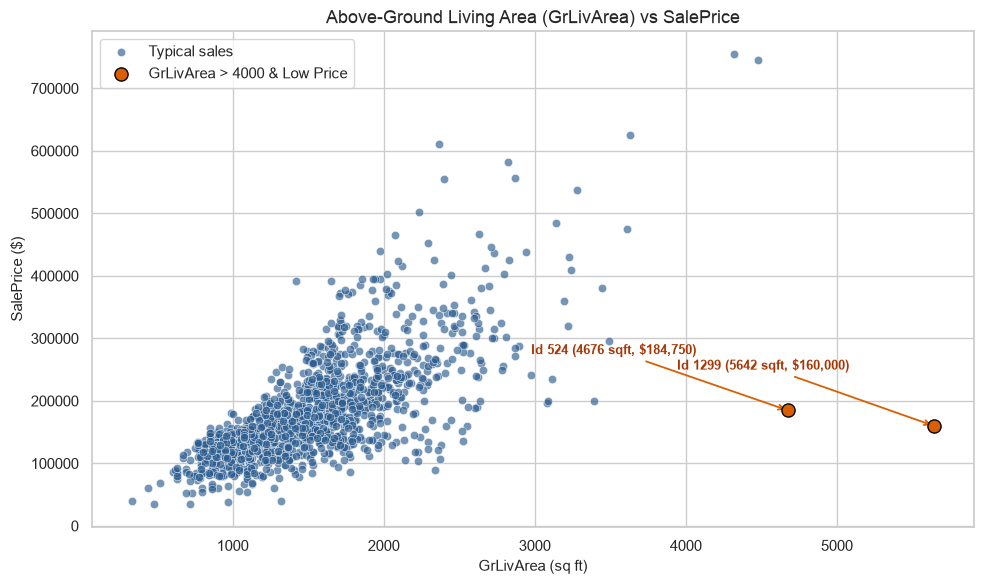

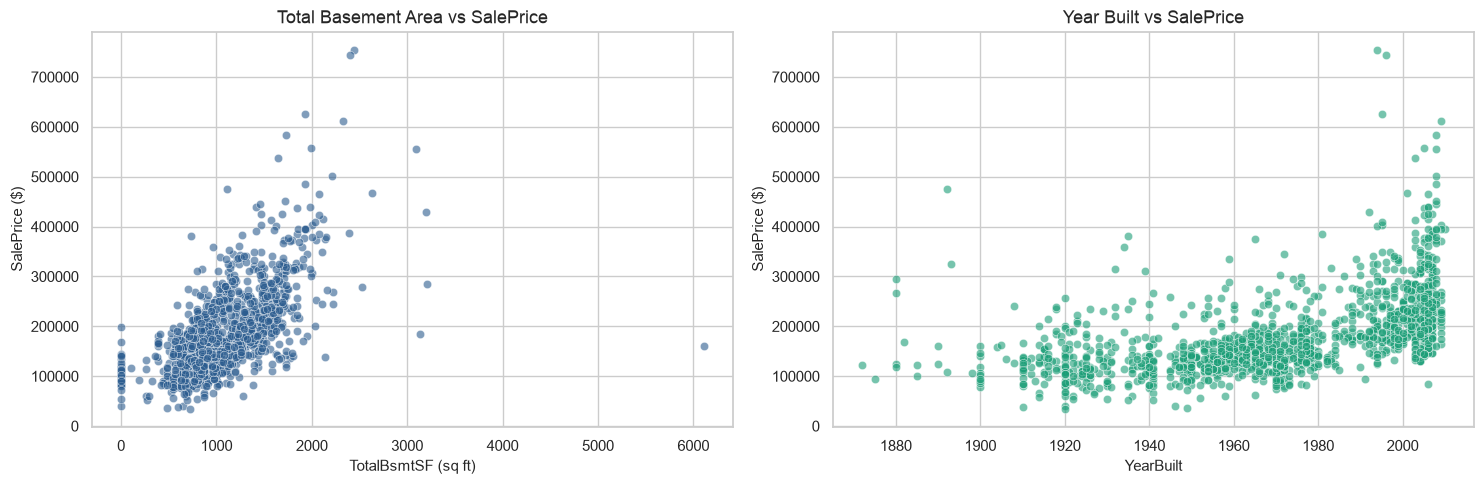

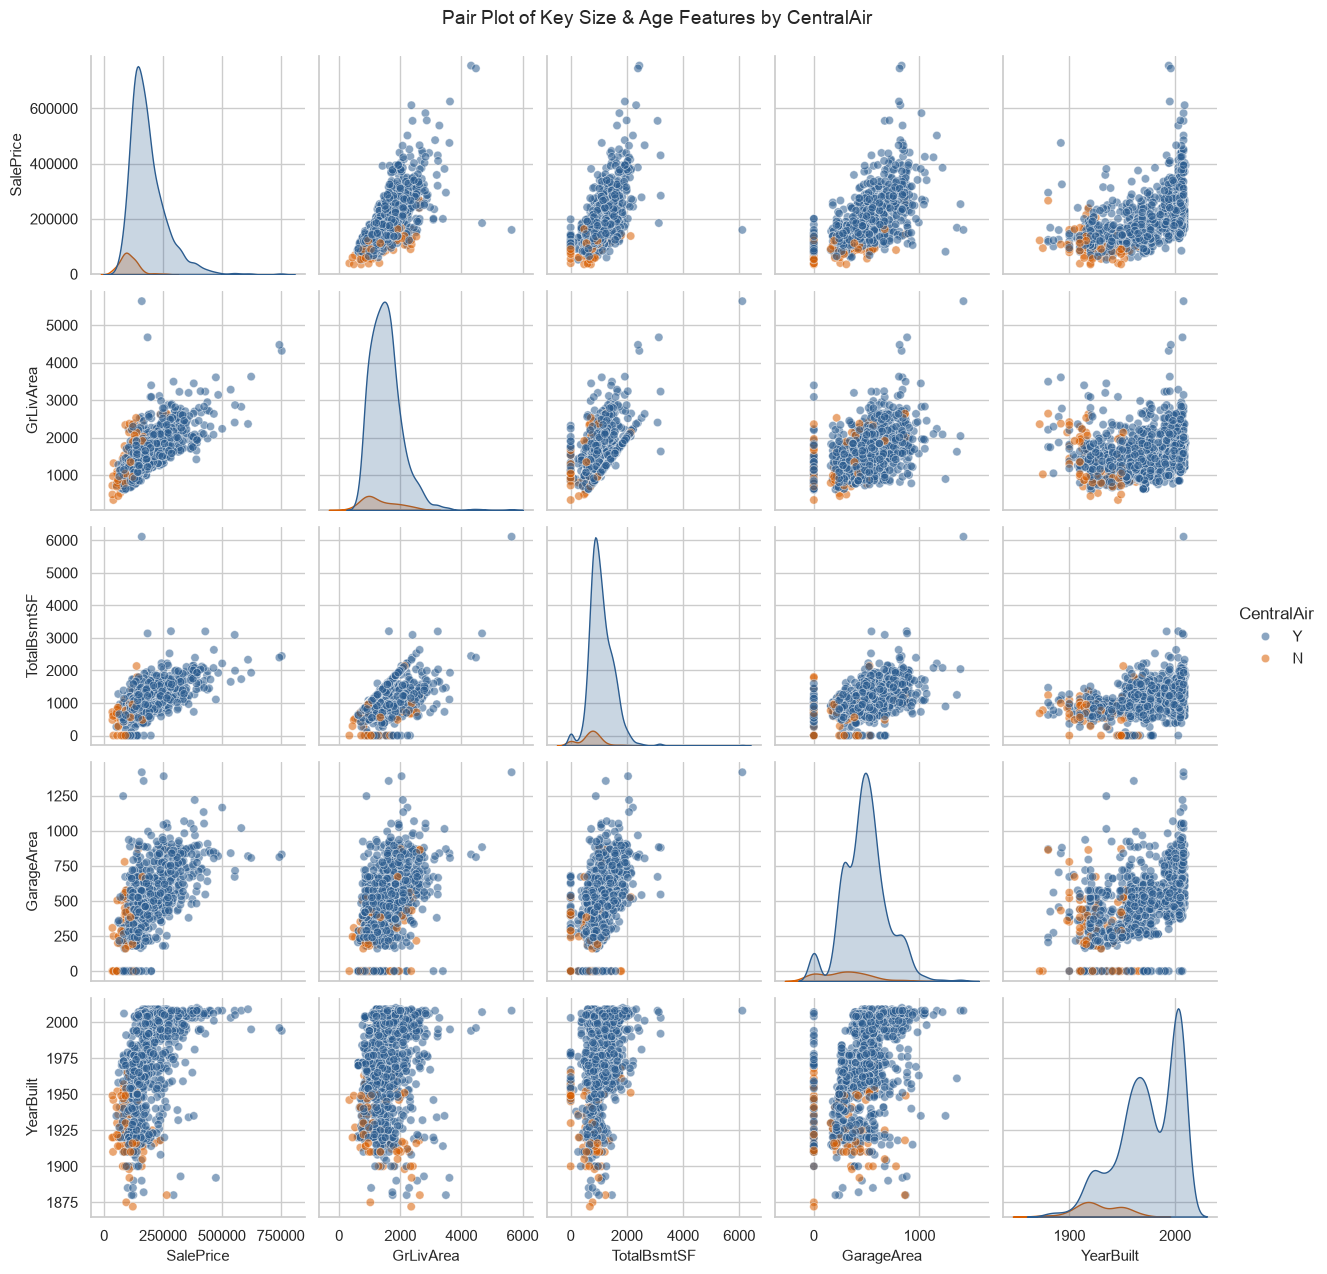

In [7]:
# Scatter: GrLivArea vs SalePrice with annotation for large area / low price
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", alpha=0.65, color="#2B5C8F", label="Typical sales")
unusual_pts = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)]
plt.scatter(unusual_pts["GrLivArea"], unusual_pts["SalePrice"],
            color="#D95F02", s=90, edgecolor="black", zorder=5,
            label="GrLivArea > 4000 & Low Price")
for _, row in unusual_pts.iterrows():
    plt.annotate(
        f"Id {int(row['Id'])} ({int(row['GrLivArea'])} sqft, ${int(row['SalePrice']):,})",
        xy=(row["GrLivArea"], row["SalePrice"]),
        xytext=(row["GrLivArea"] - 1700, row["SalePrice"] + 90000),
        arrowprops=dict(arrowstyle="->", color="#D95F02", lw=1.3),
        fontsize=9, fontweight="bold", color="#A63603"
    )
plt.title("Above-Ground Living Area (GrLivArea) vs SalePrice")
plt.xlabel("GrLivArea (sq ft)")
plt.ylabel("SalePrice ($)")
plt.legend()
plt.tight_layout()
plt.show()

# Scatter: TotalBsmtSF vs SalePrice and YearBuilt vs SalePrice
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(data=df, x="TotalBsmtSF", y="SalePrice", alpha=0.6, color="#2B5C8F", ax=axes[0])
axes[0].set_title("Total Basement Area vs SalePrice")
axes[0].set_xlabel("TotalBsmtSF (sq ft)")
axes[0].set_ylabel("SalePrice ($)")

sns.scatterplot(data=df, x="YearBuilt", y="SalePrice", alpha=0.6, color="#1B9E77", ax=axes[1])
axes[1].set_title("Year Built vs SalePrice")
axes[1].set_xlabel("YearBuilt")
axes[1].set_ylabel("SalePrice ($)")

plt.tight_layout()
plt.show()

# Pairplot coloured by CentralAir
selected = ["SalePrice", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt", "CentralAir"]
g = sns.pairplot(df[selected], hue="CentralAir", diag_kind="kde",
                 palette={"Y": "#2B5C8F", "N": "#D95F02"}, plot_kws={"alpha": 0.55})
g.figure.suptitle("Pair Plot of Key Size & Age Features by CentralAir", y=1.02, fontsize=14)
plt.show()

**What we learned (Step 6):**  
- **Clear positive trends:** `GrLivArea` and `TotalBsmtSF` show strong linear upward relationships with `SalePrice`, while `YearBuilt` shows an upward (and fanning) trend—newer homes command higher prices and have more high-end luxury variance.
- **Two striking anomalies:** In the `GrLivArea` vs `SalePrice` scatter plot, two homes with massive living areas (`Id=524`: 4,676 sq ft at \$184,750; `Id=1299`: 5,642 sq ft at \$160,000) fall dramatically below the main price-area trend. Both are `Partial` sales in `Edwards`!
- **Central air conditioning (`CentralAir`):** The pair plot reveals that homes without central air (`CentralAir = "N"`) are concentrated among older construction years (`YearBuilt < 1970`), smaller living/basement/garage footprints, and lower `SalePrice`.

### Step 7: Correlation Heatmap

**What we are about to do:**  
Build a lower-triangle correlation heatmap (with the upper triangle masked) of the 10 features most strongly correlated with `SalePrice`, plus `SalePrice` itself, using a diverging `coolwarm` palette centred at 0 and annotations rounded to 2 decimal places.

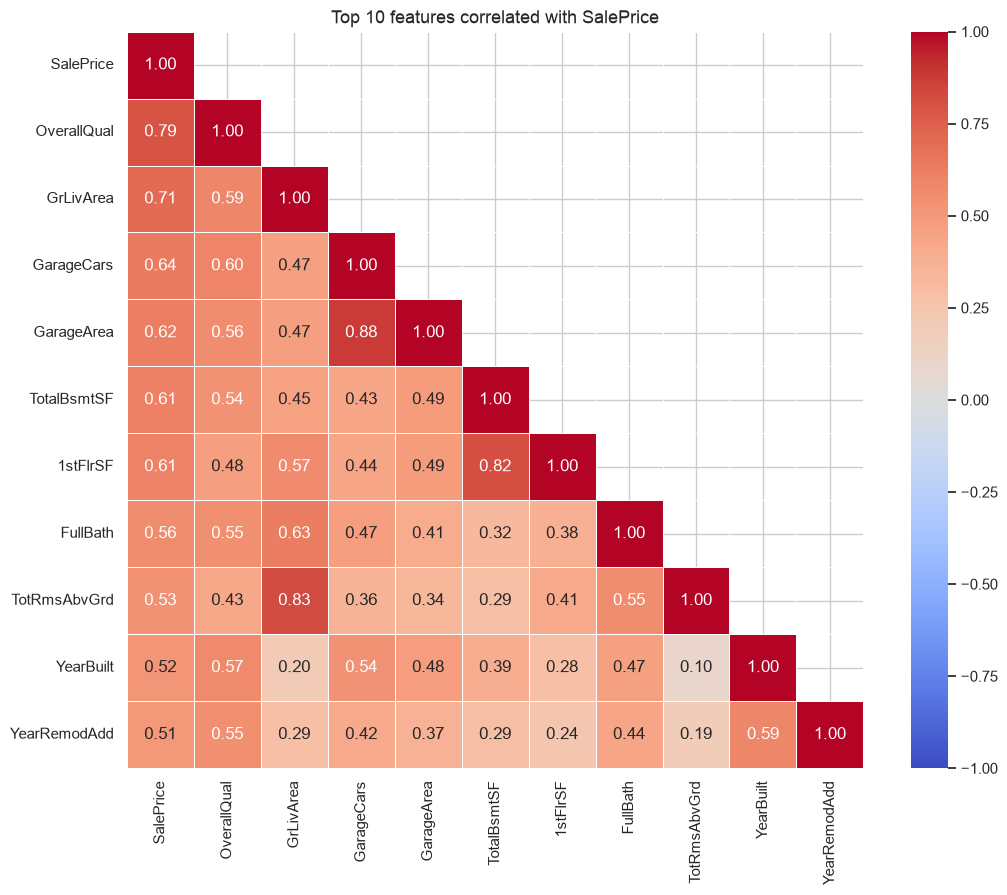

In [8]:
top10_cols = ["SalePrice"] + top_corr.head(10).index.tolist()
corr_top = df[top10_cols].corr()
mask = np.triu(np.ones_like(corr_top, dtype=bool), k=1)

plt.figure(figsize=(11, 9))
sns.heatmap(
    corr_top,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
)
plt.title("Top 10 features correlated with SalePrice")
plt.tight_layout()
plt.show()

**What we learned (Step 7):**  
- Beyond strong feature-to-`SalePrice` links (`OverallQual` 0.79, `GrLivArea` 0.71, `GarageCars` 0.64), the heatmap exposes three tight **collinear pairs** among predictors:
  - `GarageCars` & `GarageArea`: **$r = 0.88$**
  - `GrLivArea` & `TotRmsAbvGrd`: **$r = 0.83$**
  - `TotalBsmtSF` & `1stFlrSF`: **$r = 0.82$**
- `YearBuilt` and `YearRemodAdd` are also moderately correlated ($r = 0.59$) and each correlates ~0.51–0.52 with `SalePrice` and ~0.57 with `OverallQual`.

## 7. Outlier Analysis (Step 8: Outlier Detection)

**What we are about to do:**  
Implement both the **IQR rule** ($[Q_1 - 1.5 \cdot \text{IQR},\ Q_3 + 1.5 \cdot \text{IQR}]$) and the **z-score rule** ($|z| > 3$), apply both to `GrLivArea` and `SalePrice`, compare their outlier counts and overlap, inspect flagged points via boxplots and a highlighted `GrLivArea` vs `SalePrice` scatter plot, and decide whether to remove non-typical sales into `df_clean`.

--- GrLivArea ---
  IQR outliers (count):     31
  Z-score outliers (count): 16
  Overlap (both methods):   16
--- SalePrice ---
  IQR outliers (count):     61
  Z-score outliers (count): 22
  Overlap (both methods):   22


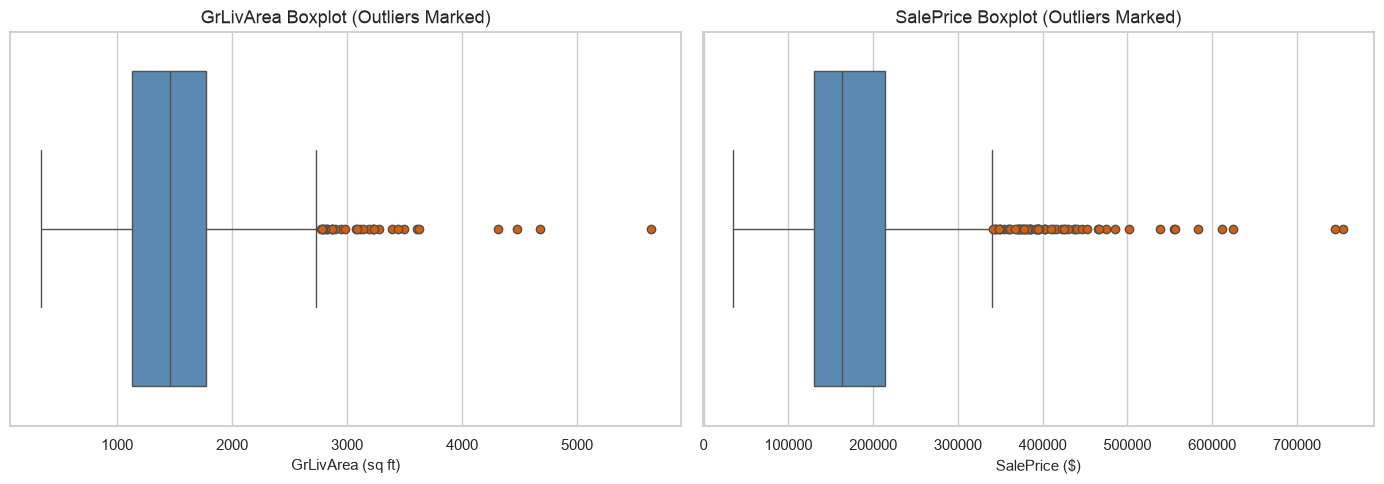

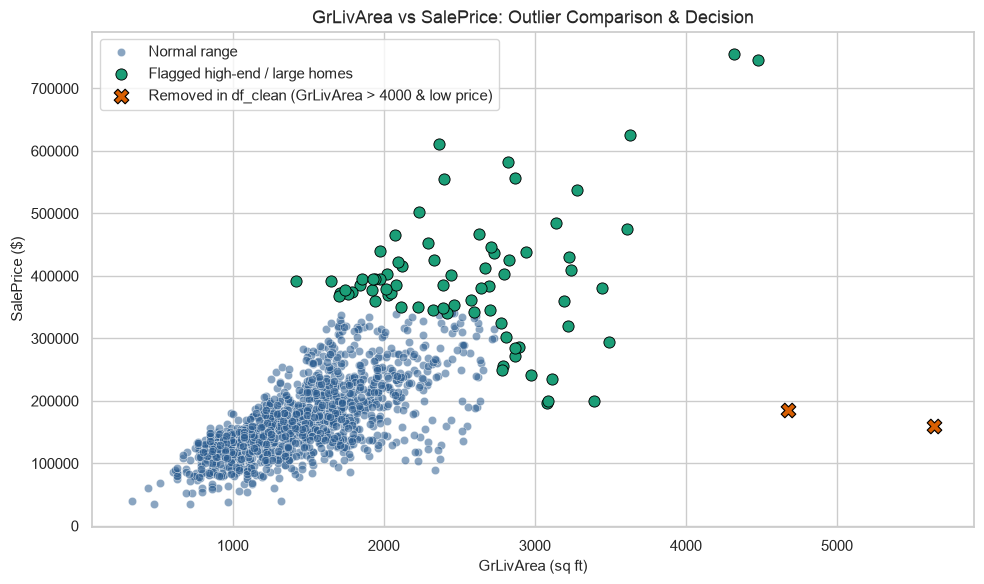


Inspecting all houses with GrLivArea > 4000 sq ft:


,Id,Neighborhood,OverallQual,GrLivArea,SalePrice,SaleCondition,YearBuilt,YearRemodAdd,YrSold
523,524,Edwards,10,4676,184750,Partial,2007,2008,2007
691,692,NoRidge,10,4316,755000,Normal,1994,1995,2007
1182,1183,NoRidge,10,4476,745000,Abnorml,1996,1996,2007
1298,1299,Edwards,10,5642,160000,Partial,2008,2008,2008


Original df shape: (1460, 81) | df_clean shape: (1458, 81)
GrLivArea-SalePrice Pearson r before: 0.7086
GrLivArea-SalePrice Pearson r after:  0.7350


In [9]:
def iqr_outliers(series: pd.Series) -> pd.Series:
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return (series < lower) | (series > upper)

def zscore_outliers(series: pd.Series, threshold: float = 3.0) -> pd.Series:
    z = (series - series.mean()) / series.std()
    return z.abs() > threshold

for col in ["GrLivArea", "SalePrice"]:
    a = iqr_outliers(df[col])
    b = zscore_outliers(df[col], threshold=3.0)
    overlap = a & b
    print(f"--- {col} ---")
    print(f"  IQR outliers (count):     {int(a.sum())}")
    print(f"  Z-score outliers (count): {int(b.sum())}")
    print(f"  Overlap (both methods):   {int(overlap.sum())}")

# Boxplots showing outliers
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x=df["GrLivArea"], color="#4C8CBF", flierprops=dict(marker="o", markerfacecolor="#D95F02"), ax=axes[0])
axes[0].set_title("GrLivArea Boxplot (Outliers Marked)")
axes[0].set_xlabel("GrLivArea (sq ft)")

sns.boxplot(x=df["SalePrice"], color="#4C8CBF", flierprops=dict(marker="o", markerfacecolor="#D95F02"), ax=axes[1])
axes[1].set_title("SalePrice Boxplot (Outliers Marked)")
axes[1].set_xlabel("SalePrice ($)")

plt.tight_layout()
plt.show()

# Scatter plot highlighting flagged points and extreme partial-sale anomalies
grliv_flagged = iqr_outliers(df["GrLivArea"]) | zscore_outliers(df["GrLivArea"])
price_flagged = iqr_outliers(df["SalePrice"]) | zscore_outliers(df["SalePrice"])
any_flagged = grliv_flagged | price_flagged
anomalous_partial = (df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df[~any_flagged], x="GrLivArea", y="SalePrice",
                alpha=0.55, color="#2B5C8F", label="Normal range")
sns.scatterplot(data=df[any_flagged & ~anomalous_partial], x="GrLivArea", y="SalePrice",
                color="#1B9E77", s=65, edgecolor="black", label="Flagged high-end / large homes")
sns.scatterplot(data=df[anomalous_partial], x="GrLivArea", y="SalePrice",
                color="#D95F02", s=110, marker="X", edgecolor="black",
                label="Removed in df_clean (GrLivArea > 4000 & low price)")
plt.title("GrLivArea vs SalePrice: Outlier Comparison & Decision")
plt.xlabel("GrLivArea (sq ft)")
plt.ylabel("SalePrice ($)")
plt.legend()
plt.tight_layout()
plt.show()

print("\nInspecting all houses with GrLivArea > 4000 sq ft:")
display(df.loc[df["GrLivArea"] > 4000,
               ["Id", "Neighborhood", "OverallQual", "GrLivArea", "SalePrice", "SaleCondition", "YearBuilt", "YearRemodAdd", "YrSold"]])

# Decision: remove only the 2 non-typical huge-area / low-price partial sales (Id 524 and Id 1299)
df_clean = df.loc[~anomalous_partial].copy()
print(f"Original df shape: {df.shape} | df_clean shape: {df_clean.shape}")
print(f"GrLivArea-SalePrice Pearson r before: {df['GrLivArea'].corr(df['SalePrice']):.4f}")
print(f"GrLivArea-SalePrice Pearson r after:  {df_clean['GrLivArea'].corr(df_clean['SalePrice']):.4f}")

**What we learned (Step 8):**  
- **Method comparison:**
  - `GrLivArea`: IQR flags **31** points; Z-score ($|z| > 3$) flags **16** points (all 16 overlap with IQR).
  - `SalePrice`: IQR flags **61** points; Z-score ($|z| > 3$) flags **22** points (all 22 overlap with IQR).
- **Inspecting extreme cases & our decision (`df_clean`):**  
  Among the 4 houses above 4,000 sq ft, `Id=692` (4,316 sq ft, \$755,000) and `Id=1183` (4,476 sq ft, \$745,000) lie cleanly along the upper price-area trajectory—they are genuine luxury homes in `NoRidge`, so we **keep** them. By contrast, `Id=524` (4,676 sq ft, \$184,750, `Partial` sale, and `YearRemodAdd=2008 > YrSold=2007`) and `Id=1299` (5,642 sq ft, \$160,000, `Partial` sale) are extreme non-typical sales that strongly distort the living-area trend. Removing just those 2 rows into `df_clean` (1,458 rows) increases the `GrLivArea`–`SalePrice` Pearson correlation from **0.7086** to **0.7350**.

**Interpretation prompt — Why does the z-score method flag fewer points on a skewed variable than the IQR method?**  
On a right-skewed distribution, extreme upper-tail observations inflate both the **mean** (shifting the centre upward) and especially the **standard deviation** (widening the spread), which pushes the $z = +3$ cutoff ($\text{mean} + 3\sigma$) very far into the tail. By contrast, $Q_1$, $Q_3$, and $\text{IQR} = Q_3 - Q_1$ are order statistics unaffected by extreme tail magnitudes, so the Tukey upper fence ($Q_3 + 1.5 \cdot \text{IQR}$) stays much tighter around the bulk of the data and flags more tail observations.

## 8. Final Dashboard and Storytelling (Step 10)

**What we are about to do:**  
Combine four complementary views into a single 2×2 summary figure (`figsize=(14, 10)`) with a consistent colour palette, clear titles, axis labels, legends, and `tight_layout()`, and save it as `eda_dashboard.png`:
1. **Panel 1 (Matplotlib line plot):** Mean `SalePrice` grouped by `YearBuilt` (`label="Average price"`).
2. **Panel 2 (Matplotlib horizontal bar plot):** Top 10 neighborhoods by mean `SalePrice`.
3. **Panel 3 (Seaborn histplot with KDE):** `SalePrice` distribution with vertical lines and legend marking the mean and median.
4. **Panel 4 (Seaborn scatter):** `GrLivArea` vs `SalePrice` coloured by `OverallQual`.

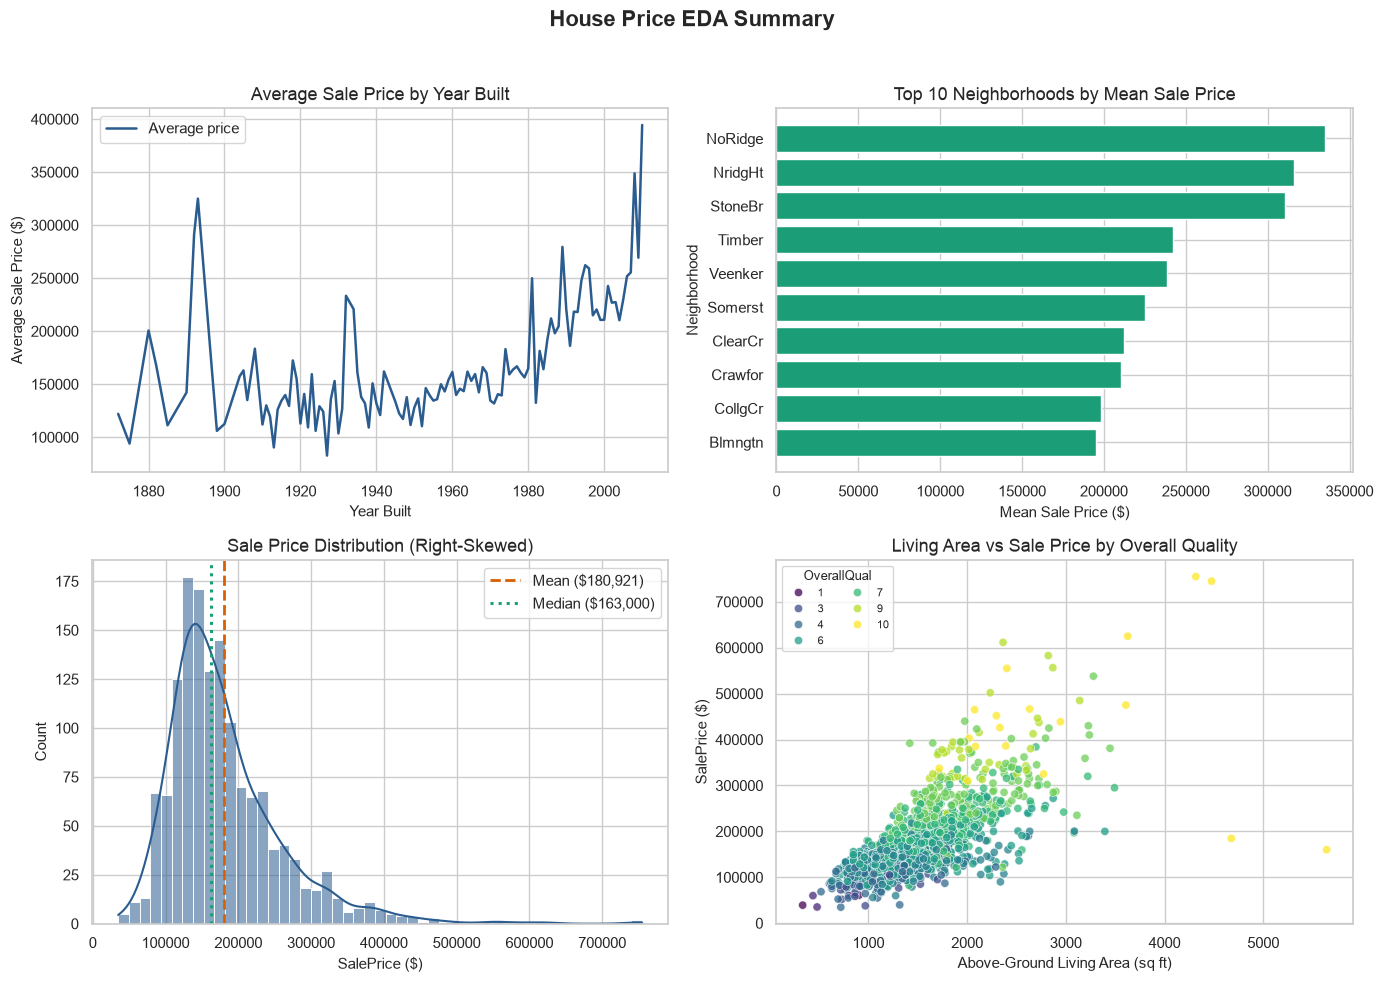

Saved final dashboard to eda_dashboard.png


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

primary_blue = "#2B5C8F"
accent_coral = "#D95F02"
accent_teal = "#1B9E77"

# Panel 1 (Matplotlib line plot): Average SalePrice by YearBuilt
year_price = df.groupby("YearBuilt")["SalePrice"].mean().sort_index()
axes[0, 0].plot(year_price.index, year_price.values, color=primary_blue, linewidth=1.8, label="Average price")
axes[0, 0].set_title("Average Sale Price by Year Built")
axes[0, 0].set_xlabel("Year Built")
axes[0, 0].set_ylabel("Average Sale Price ($)")
axes[0, 0].legend(loc="upper left")

# Panel 2 (Matplotlib horizontal bar plot): Top 10 Neighborhoods by Mean SalePrice
top10_nb = df.groupby("Neighborhood")["SalePrice"].mean().nlargest(10).sort_values()
axes[0, 1].barh(top10_nb.index, top10_nb.values, color=accent_teal)
axes[0, 1].set_title("Top 10 Neighborhoods by Mean Sale Price")
axes[0, 1].set_xlabel("Mean Sale Price ($)")
axes[0, 1].set_ylabel("Neighborhood")

# Panel 3 (Seaborn histplot with KDE): SalePrice distribution with mean & median lines
mean_price = df["SalePrice"].mean()
median_price = df["SalePrice"].median()
sns.histplot(df["SalePrice"], kde=True, color=primary_blue, alpha=0.55, ax=axes[1, 0])
axes[1, 0].axvline(mean_price, color=accent_coral, linestyle="--", linewidth=2,
                   label=f"Mean (${mean_price:,.0f})")
axes[1, 0].axvline(median_price, color=accent_teal, linestyle=":", linewidth=2.2,
                   label=f"Median (${median_price:,.0f})")
axes[1, 0].set_title("Sale Price Distribution (Right-Skewed)")
axes[1, 0].set_xlabel("SalePrice ($)")
axes[1, 0].set_ylabel("Count")
axes[1, 0].legend()

# Panel 4 (Seaborn scatter): GrLivArea vs SalePrice coloured by OverallQual
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice",
                hue="OverallQual", palette="viridis", alpha=0.75, ax=axes[1, 1])
axes[1, 1].set_title("Living Area vs Sale Price by Overall Quality")
axes[1, 1].set_xlabel("Above-Ground Living Area (sq ft)")
axes[1, 1].set_ylabel("SalePrice ($)")
axes[1, 1].legend(title="OverallQual", ncol=2, fontsize=8, title_fontsize=9, loc="upper left")

fig.suptitle("House Price EDA Summary", fontsize=16, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("eda_dashboard.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved final dashboard to eda_dashboard.png")

**What we learned (Step 10 — Dashboard Story):**  
Taken together, the four panels tell a coherent story: newer homes (`YearBuilt` after ~1990) and specific premium neighborhoods (`NoRidge`, `NridgHt`, `StoneBr`) sit at the top of the market, producing a right-skewed `SalePrice` distribution where the mean (\$180,921) outpaces the median (\$163,000), while the joint rise in `GrLivArea` and `OverallQual` explains most of the upward climb in prices—save for two rare large-area partial-sale outliers.

## 9. Conclusions and Limitations

### Answers to the Six Guiding Questions

1. **How is `SalePrice` distributed? Is it skewed?**  
   `SalePrice` is strongly **right-skewed** (skewness = **1.8829**), with a mean of **\$180,921.20** exceeding the median of **\$163,000.00** by \$17,921.20 and an IQR of **\$84,025.00**. Applying `log1p(SalePrice)` reduces skewness to **0.1213**, making it nearly normal.
2. **Which numerical features correlate most strongly with `SalePrice`?**  
   The strongest Pearson correlates are `OverallQual` ($r = 0.7910$), `GrLivArea` ($r = 0.7086$; $0.7350$ in `df_clean`), `GarageCars` ($r = 0.6404$), `GarageArea` ($r = 0.6234$), `TotalBsmtSF` ($r = 0.6136$), and `1stFlrSF` ($r = 0.6059$).
3. **Does overall quality (`OverallQual`) change price in a clear, ordered way?**  
   **Yes.** Median `SalePrice` rises monotonically across quality tiers (Spearman $\rho = 0.8098$), from \$50,150 (`OverallQual=1`) and \$133,000 (`OverallQual=5`) to \$269,750 (`OverallQual=8`) and \$432,390 (`OverallQual=10`), with spread increasing substantially at ratings 8–10.
4. **Do some neighborhoods consistently cost more than others?**  
   **Yes.** `NridgHt` (median \$315,000, mean \$316,271), `NoRidge` (median \$301,500, mean \$335,295), and `StoneBr` (median \$278,000, mean \$310,499) consistently cost far more than `MeadowV` (median \$88,000), `IDOTRR` (median \$103,000), and `BrDale` (median \$106,000).
5. **Are there outliers, and are they errors or real but unusual sales?**  
   Both. The IQR rule flags 31 `GrLivArea` and 61 `SalePrice` outliers (while z-score $|z|>3$ flags 16 and 22, respectively). High-priced estates like `Id=692` (\$755,000) and `Id=1183` (\$745,000) are real luxury homes and were kept, whereas `Id=524` (4,676 sq ft, \$184,750, `Partial` sale, `YearRemodAdd=2008 > YrSold=2007`) and `Id=1299` (5,642 sq ft, \$160,000, `Partial` sale) are non-typical sales that distort linear trends and were removed in `df_clean`.
6. **Which columns have missing values, and which of those are not truly missing?**  
   19 columns had missing values in the raw file. Fifteen categorical columns (`PoolQC`, `MiscFeature`, `Alley`, `Fence`, `MasVnrType`, `FireplaceQu`, 4 `Garage*` columns, and 5 `Bsmt*` columns) denote **"feature absent"** rather than unknown data and were filled with `"None"`, while `GarageYrBlt` (81) and `MasVnrArea` (8) reflect absent garages/veneers (`0.0`). Only `LotFrontage` (259, imputed by neighborhood median), `Electrical` (1, imputed by mode `"SBrkr"`), and two single-row basement sub-attributes represented genuine missingness.

### Verification of Expected Insights

All six expected insights from the project brief were verified against observed outputs:
1. `SalePrice` is right-skewed (1.88) and near-normal after log transform (0.12).
2. `OverallQual` ($0.79$) and `GrLivArea` ($0.71$ / $0.74$ clean) are the top correlates of `SalePrice`.
3. Price rises steadily with `OverallQual`, with larger spread at ratings 8–10.
4. `NridgHt`, `NoRidge`, and `StoneBr` stand out with clearly higher medians than the rest.
5. Two very large `Partial` sales (`Id=524`, `Id=1299`) with low prices distort the living-area trend.
6. High-missingness amenity columns represent "feature absent" and were preserved via `"None"` rather than dropped.

### Limitations

- **Correlation vs. causation:** EDA uncovers statistical associations and patterns, not causal effects (e.g., `GarageCars` and `GarageArea` are strongly collinear at $r = 0.88$, and both reflect broader house scale).
- **Geographic & temporal scope:** Findings reflect residential sales in Ames, Iowa (2006–2010) and should not be generalised blindly to other markets or time periods.
- **Univariate/bivariate limits:** Pairwise plots and correlations cannot fully isolate confounded effects (such as newer neighborhoods also having higher `OverallQual` and larger `GrLivArea`) without formal multivariate modelling, which is outside the scope of this pure-EDA project.